# QM640 Capstone — Medicare Provider Data Quality & Exploratory Data Analysis

**Project:** Predicting Medicare Payment Costs and Identifying High-Cost Provider Patterns Using Machine Learning  
**Course:** QM640 — Data Analytics Capstone | **Mentor:** Sharath Srivatsa | **Term:** Fall 2026

This notebook adapts the supplied exploratory-data-analysis workflow to the **2024 CMS Medicare Physician & Other Practitioners — by Provider** dataset. It examines data structure, provider identifiers, missingness/suppression, payment distributions, category differences, potential leakage, cross-field consistency, and extreme values.

### Previously observed baseline results

The prior analysis of the project CSV reported `1,296,739` provider-level rows and 76 columns. `Rndrng_NPI` was reported unique, with no exact duplicate rows or duplicate NPIs. The target `Tot_Mdcr_Pymt_Amt` was reported to have a mean of `$92,584.47`, median of `$26,513`, and a strongly right-skewed distribution. Eight records were reported with zero payment. Candidate high-cost cutoffs were the 90th percentile (`$151,995.92`), 95th percentile (`$261,353.12`), and 99th percentile (`$1,141,640.46`).

**Verification note:** These are previously observed baseline results, not outputs generated by this notebook run. The cells below recalculate the statistics from the CSV you select. If the file version differs, use the newly generated outputs as authoritative and update any written report accordingly.

**Important boundaries:** The unit of analysis is a provider/NPI aggregate, not a patient or claim. The data describe the CMS reporting scope, not all provider revenue or all healthcare coverage. High payment is not evidence of fraud, waste, abuse, or poor quality. Do not replace suppressed/missing values with zero, and do not automatically cap or delete high-payment records.


## 1. Context, research alignment, and project boundaries

This EDA prepares the dataset for the capstone research questions:

- **RQ1 — Group differences:** What provider, utilization, and beneficiary characteristics are associated with differences in Medicare payment costs?
- **RQ2 — Payment prediction:** Which eligible provider, utilization, and beneficiary characteristics predict payment amounts?
- **RQ3 — High-cost classification:** Which model most accurately identifies providers in a pre-defined high-cost group?
- **RQ4 — Risk scoring:** Can a provider-level score prioritize records for payment/utilization review?

The notebook does not answer these questions inferentially by itself. It creates data-quality evidence and descriptive outputs that inform later hypothesis tests and predictive modeling.

**Target planned for modeling:** `Tot_Mdcr_Pymt_Amt`.

**Potential leakage/timing concern:** Payment-related fields such as `Tot_Mdcr_Alowd_Amt` and `Tot_Mdcr_Stdzd_Amt`, and potentially submitted charges or service counts, must be reviewed against the intended prediction time. Do not use variables that directly encode the outcome or would not be available when the prediction is supposed to be made.

**Official source resources**
- CMS dataset: https://data.cms.gov/provider-summary-by-type-of-service/medicare-physician-other-practitioners/medicare-physician-other-practitioners-by-provider
- CMS API documentation: https://data.cms.gov/provider-summary-by-type-of-service/medicare-physician-other-practitioners/medicare-physician-other-practitioners-by-provider/api-docs
- CMS data dictionary: https://data.cms.gov/resources/medicare-physician-other-practitioners-by-provider-data-dictionary


## 2. Import libraries and set options

In [1]:
from pathlib import Path
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 120)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

## 3. Load the CMS file

Set `DATA_PATH` to the downloaded CSV. In Google Colab, upload the file or mount Drive and update this path. Avoid hard-coded personal Drive paths in the public repository.

In [2]:
# let colab access my google drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
OUTPUT_DIR = Path("/content/drive/MyDrive/AI_ML-MS/Capstone Project/qm640_project/reports/eda")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42
print("Output directory:", OUTPUT_DIR.resolve())

Output directory: /content/drive/MyDrive/AI_ML-MS/Capstone Project/qm640_project/reports/eda


In [4]:
# Update this path for your environment.
#DATA_PATH = Path("data/raw/cms_provider_2024.csv")
# If running in Colab and the file was uploaded to the session, you may use:
DATA_PATH = Path("/content/drive/MyDrive/AI_ML-MS/Capstone Project/Capstone_cms_provider_2024.csv")

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"CSV not found at {DATA_PATH.resolve()}. Download the official CMS file, "
        "place it at data/raw/cms_provider_2024.csv, or update DATA_PATH."
    )

data = pd.read_csv(DATA_PATH, low_memory=False)
print(f"Rows: {data.shape[0]:,} | Columns: {data.shape[1]:,}")
display(data.head())
display(data.tail())

Rows: 1,296,739 | Columns: 76


,Rndrng_NPI,Rndrng_Prvdr_Last_Org_Name,Rndrng_Prvdr_First_Name,Rndrng_Prvdr_Ent_Cd,Rndrng_Prvdr_State_Abrvtn,Rndrng_Prvdr_State_FIPS,Rndrng_Prvdr_Zip5,Rndrng_Prvdr_RUCA,Rndrng_Prvdr_RUCA_Desc,Rndrng_Prvdr_Cntry,Rndrng_Prvdr_Type,Rndrng_Prvdr_Mdcr_Prtcptg_Ind,Tot_HCPCS_Cds,Tot_Benes,Tot_Srvcs,Tot_Sbmtd_Chrg,Tot_Mdcr_Alowd_Amt,Tot_Mdcr_Pymt_Amt,Tot_Mdcr_Stdzd_Amt,Drug_Sprsn_Ind,Drug_Tot_HCPCS_Cds,Drug_Tot_Benes,Drug_Tot_Srvcs,Drug_Sbmtd_Chrg,Drug_Mdcr_Alowd_Amt,Drug_Mdcr_Pymt_Amt,Drug_Mdcr_Stdzd_Amt,Med_Sprsn_Ind,Med_Tot_HCPCS_Cds,Med_Tot_Benes,Med_Tot_Srvcs,Med_Sbmtd_Chrg,Med_Mdcr_Alowd_Amt,Med_Mdcr_Pymt_Amt,Med_Mdcr_Stdzd_Amt,Bene_Avg_Age,Bene_Age_LT_65_Cnt,Bene_Age_65_74_Cnt,Bene_Age_75_84_Cnt,Bene_Age_GT_84_Cnt,Bene_Feml_Cnt,Bene_Male_Cnt,Bene_Race_Wht_Cnt,Bene_Race_Black_Cnt,Bene_Race_API_Cnt,Bene_Race_Hspnc_Cnt,Bene_Race_NatInd_Cnt,Bene_Race_Othr_Cnt,Bene_Dual_Cnt,Bene_Ndual_Cnt,Bene_Avg_Risk_Scre,Bene_CC_BH_ADHD_OthCD_V1_Pct,Bene_CC_BH_Alcohol_Drug_V1_Pct,Bene_CC_BH_Tobacco_V1_Pct,Bene_CC_BH_Alz_NonAlzdem_V2_Pct,Bene_CC_BH_Anxiety_V1_Pct,Bene_CC_BH_Bipolar_V1_Pct,Bene_CC_BH_Mood_V2_Pct,Bene_CC_BH_Depress_V1_Pct,Bene_CC_BH_PD_V1_Pct,Bene_CC_BH_PTSD_V1_Pct,Bene_CC_BH_Schizo_OthPsy_V1_Pct,Bene_CC_PH_Asthma_V2_Pct,Bene_CC_PH_Afib_V2_Pct,Bene_CC_PH_Cancer6_V2_Pct,Bene_CC_PH_CKD_V2_Pct,Bene_CC_PH_COPD_V2_Pct,Bene_CC_PH_Diabetes_V2_Pct,Bene_CC_PH_HF_NonIHD_V2_Pct,Bene_CC_PH_Hyperlipidemia_V2_Pct,Bene_CC_PH_Hypertension_V2_Pct,Bene_CC_PH_IschemicHeart_V2_Pct,Bene_CC_PH_Osteoporosis_V2_Pct,Bene_CC_PH_Parkinson_V2_Pct,Bene_CC_PH_Arthritis_V2_Pct,Bene_CC_PH_Stroke_TIA_V2_Pct
0,1003000126,Enkeshafi,Ardalan,I,MD,24,20817,1.0000,Metropolitan area core: primary flow within an...,US,Internal Medicine,Y,15,328,399.0000,"202,783.8800","46,472.6500","35,325.4600","34,781.0100",NaN,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,NaN,15.0000,328.0000,399.0000,"202,783.8800","46,472.6500","35,325.4600","34,781.0100",76,37.0000,94.0000,130.0000,67.0000,171.0000,157.0000,281.0000,21.0000,NaN,NaN,NaN,NaN,77.0000,251.0000,2.5660,NaN,15.0000,19.0000,27.0000,46.0000,9.0000,52.0000,48.0000,NaN,NaN,5.0000,17.0000,39.0000,27.0000,55.0000,38.0000,48.0000,48.0000,75.0000,75.0000,51.0000,18.0000,4.0000,63.0000,21.0000
1,1003000134,Cibull,Thomas,I,IL,17,60201,1.0000,Metropolitan area core: primary flow within an...,US,Pathology,Y,21,912,"2,023.0000","302,581.0000","69,422.5900","50,178.1100","47,710.6100",NaN,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,NaN,21.0000,912.0000,"2,023.0000","302,581.0000","69,422.5900","50,178.1100","47,710.6100",76,16.0000,419.0000,337.0000,140.0000,455.0000,457.0000,806.0000,13.0000,29.0000,23.0000,0.0000,41.0000,48.0000,864.0000,1.1958,NaN,3.0000,4.0000,5.0000,16.0000,3.0000,20.0000,17.0000,1.0000,NaN,NaN,6.0000,17.0000,17.0000,21.0000,10.0000,23.0000,14.0000,75.0000,64.0000,26.0000,15.0000,2.0000,47.0000,6.0000
2,1003000142,Khalil,Rashid,I,OH,39,43623,1.0000,Metropolitan area core: primary flow within an...,US,Anesthesiology,Y,41,316,"1,369.0000","381,301.0000","133,096.8400","101,577.9400","103,554.7500",NaN,2.0000,20.0000,261.0000,"4,154.0000",29.8700,23.8000,23.8000,NaN,39.0000,316.0000,"1,108.0000","377,147.0000","133,066.9700","101,554.1400","103,530.9500",70,84.0000,127.0000,84.0000,21.0000,192.0000,124.0000,199.0000,97.0000,NaN,NaN,0.0000,NaN,112.0000,204.0000,1.6931,NaN,20.0000,21.0000,7.0000,53.0000,7.0000,46.0000,44.0000,NaN,4.0000,5.0000,15.0000,17.0000,12.0000,34.0000,32.0000,45.0000,27.0000,75.0000,75.0000,36.0000,17.0000,NaN,75.0000,11.0000
3,1003000423,Velotta,Jennifer,I,OH,39,44060,1.0000,Metropolitan area core: primary flow within an...,US,Obstetrics & Gynecology,Y,18,75,140.0000,"22,015.0000","8,708.7400","7,134.3200","7,502.2100",NaN,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,NaN,18.0000,75.0000,140.0000,"22,015.0000","8,708.7400","7,134.3200","7,502.2100",70,NaN,50.0000,NaN,NaN,75.0000,0.0000,NaN,NaN,NaN,NaN,NaN,NaN,11.0000,64.0000,0.7931,NaN,NaN,NaN,NaN,35.0000,NaN,29.0000,28.0000,NaN,NaN,Na

,Rndrng_NPI,Rndrng_Prvdr_Last_Org_Name,Rndrng_Prvdr_First_Name,Rndrng_Prvdr_Ent_Cd,Rndrng_Prvdr_State_Abrvtn,Rndrng_Prvdr_State_FIPS,Rndrng_Prvdr_Zip5,Rndrng_Prvdr_RUCA,Rndrng_Prvdr_RUCA_Desc,Rndrng_Prvdr_Cntry,Rndrng_Prvdr_Type,Rndrng_Prvdr_Mdcr_Prtcptg_Ind,Tot_HCPCS_Cds,Tot_Benes,Tot_Srvcs,Tot_Sbmtd_Chrg,Tot_Mdcr_Alowd_Amt,Tot_Mdcr_Pymt_Amt,Tot_Mdcr_Stdzd_Amt,Drug_Sprsn_Ind,Drug_Tot_HCPCS_Cds,Drug_Tot_Benes,Drug_Tot_Srvcs,Drug_Sbmtd_Chrg,Drug_Mdcr_Alowd_Amt,Drug_Mdcr_Pymt_Amt,Drug_Mdcr_Stdzd_Amt,Med_Sprsn_Ind,Med_Tot_HCPCS_Cds,Med_Tot_Benes,Med_Tot_Srvcs,Med_Sbmtd_Chrg,Med_Mdcr_Alowd_Amt,Med_Mdcr_Pymt_Amt,Med_Mdcr_Stdzd_Amt,Bene_Avg_Age,Bene_Age_LT_65_Cnt,Bene_Age_65_74_Cnt,Bene_Age_75_84_Cnt,Bene_Age_GT_84_Cnt,Bene_Feml_Cnt,Bene_Male_Cnt,Bene_Race_Wht_Cnt,Bene_Race_Black_Cnt,Bene_Race_API_Cnt,Bene_Race_Hspnc_Cnt,Bene_Race_NatInd_Cnt,Bene_Race_Othr_Cnt,Bene_Dual_Cnt,Bene_Ndual_Cnt,Bene_Avg_Risk_Scre,Bene_CC_BH_ADHD_OthCD_V1_Pct,Bene_CC_BH_Alcohol_Drug_V1_Pct,Bene_CC_BH_Tobacco_V1_Pct,Bene_CC_BH_Alz_NonAlzdem_V2_Pct,Bene_CC_BH_Anxiety_V1_Pct,Bene_CC_BH_Bipolar_V1_Pct,Bene_CC_BH_Mood_V2_Pct,Bene_CC_BH_Depress_V1_Pct,Bene_CC_BH_PD_V1_Pct,Bene_CC_BH_PTSD_V1_Pct,Bene_CC_BH_Schizo_OthPsy_V1_Pct,Bene_CC_PH_Asthma_V2_Pct,Bene_CC_PH_Afib_V2_Pct,Bene_CC_PH_Cancer6_V2_Pct,Bene_CC_PH_CKD_V2_Pct,Bene_CC_PH_COPD_V2_Pct,Bene_CC_PH_Diabetes_V2_Pct,Bene_CC_PH_HF_NonIHD_V2_Pct,Bene_CC_PH_Hyperlipidemia_V2_Pct,Bene_CC_PH_Hypertension_V2_Pct,Bene_CC_PH_IschemicHeart_V2_Pct,Bene_CC_PH_Osteoporosis_V2_Pct,Bene_CC_PH_Parkinson_V2_Pct,Bene_CC_PH_Arthritis_V2_Pct,Bene_CC_PH_Stroke_TIA_V2_Pct
1296734,1992999569,Yuen,Jenny,I,CA,06,94102,1.0000,Metropolitan area core: primary flow within an...,US,Optometry,Y,5,22,37.0000,"5,230.0000","4,475.2800","3,058.5400","2,426.3200",NaN,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,NaN,5.0000,22.0000,37.0000,"5,230.0000","4,475.2800","3,058.5400","2,426.3200",75,NaN,11.0000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.7468,NaN,NaN,0.0000,NaN,NaN,0.0000,NaN,NaN,0.0000,0.0000,0.0000,NaN,NaN,NaN,NaN,0.0000,NaN,NaN,68.0000,59.0000,NaN,NaN,NaN,NaN,NaN
1296735,1992999775,"Spine Surgery Center Of Eugene, Llc",NaN,O,OR,41,97401,1.0000,Metropolitan area core: primary flow within an...,US,Ambulatory Surgical Center,Y,25,271,405.0000,"3,040,195.0000","1,109,154.5100","881,042.0100","800,554.3100",NaN,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,NaN,25.0000,271.0000,405.0000,"3,040,195.0000","1,109,154.5100","881,042.0100","800,554.3100",73,20.0000,138.0000,97.0000,16.0000,137.0000,134.0000,260.0000,0.0000,NaN,NaN,0.0000,NaN,18.0000,253.0000,1.0173,NaN,6.0000,11.0000,NaN,20.0000,NaN,24.0000,23.0000,NaN,4.0000,NaN,13.0000,14.0000,12.0000,18.0000,16.0000,23.0000,12.0000,71.0000,73.0000,21.0000,13.0000,NaN,75.0000,6.0000
1296736,1992999817,Takenishi,Greg,I,CA,06,95816,1.0000,Metropolitan area core: primary flow within an...,US,Orthopedic Surgery,Y,39,135,421.0000,"212,002.0400","79,414.5900","62,324.7600","58,330.9400",*,NaN,NaN,NaN,NaN,NaN,NaN,NaN,#,NaN,NaN,NaN,NaN,NaN,NaN,NaN,74,NaN,66.0000,50.0000,NaN,86.0000,49.0000,109.0000,NaN,NaN,NaN,0.0000,NaN,NaN,NaN,0.9909,NaN,NaN,NaN,NaN,26.0000,NaN,20.0000,19.0000,NaN,NaN,NaN,14.0000,16.0000,15.0000,19.0000,14.0000,20.0000,13.0000,75.0000,67.0000,16.0000,22.0000,NaN,75.0000,NaN
1296737,1992999825,Deschenes,Geoffrey,I,WA,53,98101,1.0000,Metropolitan area core: primary flow within an...,US,Otolaryngology,Y,33,318,529.0000,"191,746.1000","73,067.3300","53,875.3100","48,037.3400",*,NaN,NaN,NaN,NaN,NaN,NaN,NaN,#,NaN,NaN,NaN,NaN,NaN,NaN,NaN,75,13.0000,137.0000,130.0000,38.0000,177.0000,141.0000,276.0000,NaN,12.0000,NaN,NaN,15.0000,20.0000,298.0000,1.0919,NaN,4.0000,NaN,8.0000,25.0000,NaN,23.0000,21.0000,NaN,3.0000,NaN,10.0000,18.0000,18.0000,14.0000,10.0000,21.0000,17.0000,66.0000,57.0000,19.0000,17.0000,NaN,46.0000,6.0000
1296738,1992999874,Joffe,Gabriella,I,VA,51,23227,1.0000,Metropolitan area core: primary flow within an...,US,Internal Medicine,Y,6,311,640.0000,"230,706.000

## 4. Dataset structure and schema

Check row/column count, column names, inferred types, memory use, and examples. Do not assume the schema matches a previous download; record the actual schema of the file used for each run.

In [5]:
schema = pd.DataFrame({
    "column": data.columns,
    "dtype": [str(data[c].dtype) for c in data.columns],
    "non_null_count": [int(data[c].notna().sum()) for c in data.columns],
    "missing_count": [int(data[c].isna().sum()) for c in data.columns],
    "missing_pct": [float(data[c].isna().mean() * 100) for c in data.columns],
    "n_unique_non_null": [int(data[c].nunique(dropna=True)) for c in data.columns],
})
display(schema.sort_values(["missing_pct", "column"], ascending=[False, True]))
schema.to_csv(OUTPUT_DIR / "column_profile.csv", index=False)

data.info(memory_usage="deep")

,column,dtype,non_null_count,missing_count,missing_pct,n_unique_non_null
19,Drug_Sprsn_Ind,object,151696,1145043,88.3017,2
27,Med_Sprsn_Ind,object,151696,1145043,88.3017,2
44,Bene_Race_API_Cnt,float64,234199,1062540,81.9394,1075
47,Bene_Race_Othr_Cnt,float64,244139,1052600,81.1728,771
45,Bene_Race_Hspnc_Cnt,float64,307853,988886,76.2594,1362
43,Bene_Race_Black_Cnt,float64,371840,924899,71.3250,1526
60,Bene_CC_BH_PTSD_V1_Pct,float64,414570,882169,68.0298,76
51,Bene_CC_BH_ADHD_OthCD_V1_Pct,float64,421715,875024,67.4788,76
59,Bene_CC_BH_PD_V1_Pct,float64,444663,852076,65.7091,76
46,Bene_Race_NatInd_Cnt,float64,447859,848880,65.4627,448


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1296739 entries, 0 to 1296738
Data columns (total 76 columns):
 #   Column                            Non-Null Count    Dtype  
---  ------                            --------------    -----  
 0   Rndrng_NPI                        1296739 non-null  int64  
 1   Rndrng_Prvdr_Last_Org_Name        1296739 non-null  object 
 2   Rndrng_Prvdr_First_Name           1235756 non-null  object 
 3   Rndrng_Prvdr_Ent_Cd               1296739 non-null  object 
 4   Rndrng_Prvdr_State_Abrvtn         1296739 non-null  object 
 5   Rndrng_Prvdr_State_FIPS           1296738 non-null  object 
 6   Rndrng_Prvdr_Zip5                 1296738 non-null  object 
 7   Rndrng_Prvdr_RUCA                 1295902 non-null  float64
 8   Rndrng_Prvdr_RUCA_Desc            1295902 non-null  object 
 9   Rndrng_Prvdr_Cntry                1296739 non-null  object 
 10  Rndrng_Prvdr_Type                 1296739 non-null  object 
 11  Rndrng_Prvdr_Mdcr_Prtcptg_Ind     129

## 5. Sanity checks: keys, duplicates, and empty fields

The expected provider identifier is generally `Rndrng_NPI`; confirm the column exists before interpreting key checks. Exact duplicate rows and duplicate identifiers are separate checks.


In [6]:
NPI_COL = "Rndrng_NPI"
TARGET = "Tot_Mdcr_Pymt_Amt"

print("Exact duplicate rows:", int(data.duplicated().sum()))
print("All-empty rows:", int(data.isna().all(axis=1).sum()))
print("All-empty columns:", int(data.isna().all(axis=0).sum()))

if NPI_COL in data.columns:
    print("Missing provider IDs:", int(data[NPI_COL].isna().sum()))
    print("Duplicate non-null provider IDs:", int(data.loc[data[NPI_COL].notna(), NPI_COL].duplicated().sum()))
else:
    print(f"WARNING: expected identifier {NPI_COL!r} is absent. Inspect the data dictionary and actual schema.")

if TARGET in data.columns:
    print("Missing target values:", int(data[TARGET].isna().sum()))
else:
    print(f"WARNING: expected target {TARGET!r} is absent. Check the file version and data dictionary.")

Exact duplicate rows: 0
All-empty rows: 0
All-empty columns: 0
Missing provider IDs: 0
Duplicate non-null provider IDs: 0
Missing target values: 0


## 6. Missingness and potential suppression

Compute missing counts and percentages for all columns and visualize the fields with the highest missingness. Missing values can arise from suppression, non-applicability, or unavailable reporting; they are not necessarily data-entry errors. Consult the CMS dictionary before imputation. Do not fill missing or suppressed values with zero unless the source definition explicitly says that zero is the correct value.

,column,missing_count,missing_pct
27,Med_Sprsn_Ind,1145043,88.3017
19,Drug_Sprsn_Ind,1145043,88.3017
44,Bene_Race_API_Cnt,1062540,81.9394
47,Bene_Race_Othr_Cnt,1052600,81.1728
45,Bene_Race_Hspnc_Cnt,988886,76.2594
43,Bene_Race_Black_Cnt,924899,71.3250
60,Bene_CC_BH_PTSD_V1_Pct,882169,68.0298
51,Bene_CC_BH_ADHD_OthCD_V1_Pct,875024,67.4788
59,Bene_CC_BH_PD_V1_Pct,852076,65.7091
46,Bene_Race_NatInd_Cnt,848880,65.4627


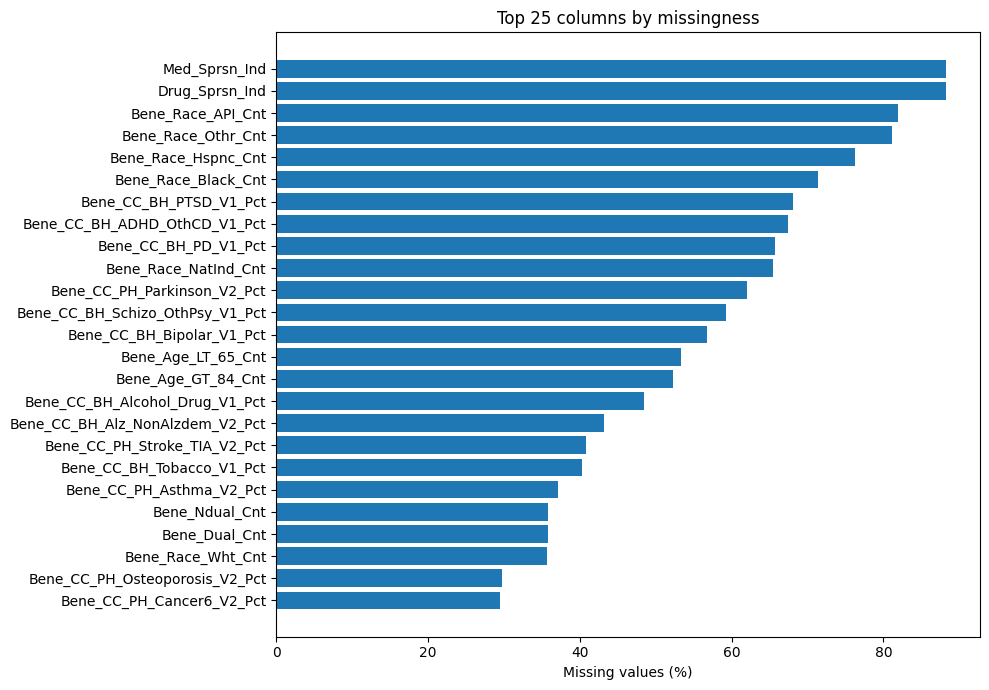

In [7]:
missingness = schema[["column", "missing_count", "missing_pct"]].sort_values("missing_pct", ascending=False)
display(missingness.head(30))
missingness.to_csv(OUTPUT_DIR / "missingness.csv", index=False)

top_missing = missingness.loc[missingness["missing_count"] > 0].head(25).sort_values("missing_pct")
if not top_missing.empty:
    plt.figure(figsize=(10, max(5, 0.28 * len(top_missing))))
    plt.barh(top_missing["column"], top_missing["missing_pct"])
    plt.xlabel("Missing values (%)")
    plt.title("Top 25 columns by missingness")
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "missingness_top25.png", dpi=160, bbox_inches="tight")
    plt.show()
else:
    print("No missing values found.")

## 7. Numeric summaries and domain sanity checks

Review distribution summaries, negative values, zeros, and infinite values. A statistical outlier is only a flag for investigation, not proof of invalid data. Payment and utilization totals can be highly skewed and large values may be legitimate.

In [8]:
numeric_cols = data.select_dtypes(include=np.number).columns.tolist()
if numeric_cols:
    numeric_summary = data[numeric_cols].describe(percentiles=[.01, .05, .25, .50, .75, .90, .95, .99]).T
    numeric_summary["missing_count"] = data[numeric_cols].isna().sum()
    numeric_summary["zero_count"] = (data[numeric_cols] == 0).sum()
    numeric_summary["negative_count"] = (data[numeric_cols] < 0).sum()
    numeric_summary["infinite_count"] = np.isinf(data[numeric_cols]).sum()
    display(numeric_summary)
    numeric_summary.to_csv(OUTPUT_DIR / "numeric_summary.csv")
else:
    print("No numeric columns detected; inspect import dtypes and source formatting.")

,count,mean,std,min,1%,5%,25%,50%,75%,90%,95%,99%,max,missing_count,zero_count,negative_count,infinite_count
Rndrng_NPI,"1,296,739.0000","1,499,666,560.7377","287,845,339.9357","1,003,000,126.0000","1,003,995,728.5800","1,053,038,152.2000","1,245,954,705.0000","1,497,955,058.0000","1,740,940,424.0000","1,891,997,915.4000","1,952,004,240.1000","1,982,999,662.4200","1,992,999,874.0000",0,0,0,0
Rndrng_Prvdr_RUCA,"1,295,902.0000",1.5955,3.2562,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,4.0000,4.0000,10.0000,99.0000,837,0,0,0
Tot_HCPCS_Cds,"1,296,739.0000",25.5917,27.9174,1.0000,1.0000,3.0000,8.0000,16.0000,34.0000,57.0000,77.0000,140.0000,833.0000,0,0,0,0
Tot_Benes,"1,296,739.0000",281.4658,"2,678.7820",11.0000,11.0000,16.0000,52.0000,130.0000,282.0000,551.0000,882.0000,"2,410.0000","1,560,327.0000",0,0,0,0
Tot_Srvcs,"1,296,739.0000","2,707.4299","45,638.9180",11.0000,17.0000,35.0000,151.0000,433.0000,"1,280.0000","3,455.0000","6,227.0000","32,285.8720","19,319,499.7000",0,0,0,0
Tot_Sbmtd_Chrg,"1,296,739.0000","380,955.5592","3,336,994.2301",31.6900,"2,614.6090","7,201.0360","37,152.0000","110,623.7800","293,178.6100","678,051.6080","1,160,369.0200","4,428,116.7548","1,286,033,410.6000",0,0,0,0
Tot_Mdcr_Alowd_Amt,"1,296,739.0000","117,336.2895","849,026.7257",26.4000,"1,095.5490","2,735.8230","12,783.3450","34,698.5400","86,273.8050","196,772.4780","338,109.9990","1,438,059.6486","306,357,782.6800",0,0,0,0
Tot_Mdcr_Pymt_Amt,"1,296,739.0000","92,584.4736","769,861.1684",0.0000,779.3200,"2,021.6880","9,634.9550","26,513.0000","66,672.4050","151,995.9200","261,353.1230","1,141,640.4648","306,357,782.6800",0,8,0,0
Tot_Mdcr_Stdzd_Amt,"1,296,739.0000","91,981.6949","762,279.1651",0.0000,797.5076,"2,023.5280","9,667.1900","26,596.7700","66,526.6050","150,591.4640","257,460.5700","1,136,946.6024","306,446,999.7600",0,6,0,0
Drug_Tot_HCPCS_Cds,"1,145,043.0000",1.6027,5.5659,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,6.0000,8.0000,15.0000,146.0000,151696,891095,0,0


## 8. Target distribution: total Medicare payment

The supplied EDA run reports a strongly right-skewed target: mean `$92,584.47`  versus median `$26,513.00`, with a 99th percentile of `$1,141,640.46` and maximum of `$306,357,782.68`. The code below recalculates the distribution for the selected CSV. Use the results from the current run in the final report.

Candidate high-cost thresholds are data-derived operational definitions, not official CMS risk labels. A percentile-based threshold should be fixed before model evaluation to avoid defining the target using test-set information. For the capstone, the 90th percentile is a practical initial candidate; compare alternatives only as a documented sensitivity analysis.


,total_medicare_payment
count,"1,296,739.0000"
mean,"92,584.4736"
std,"769,861.1684"
min,0.0000
50%,"26,513.0000"
75%,"66,672.4050"
90%,"151,995.9200"
95%,"261,353.1230"
99%,"1,141,640.4648"
max,"306,357,782.6800"


Missing: 0
Zeros: 8
Negative values: 0


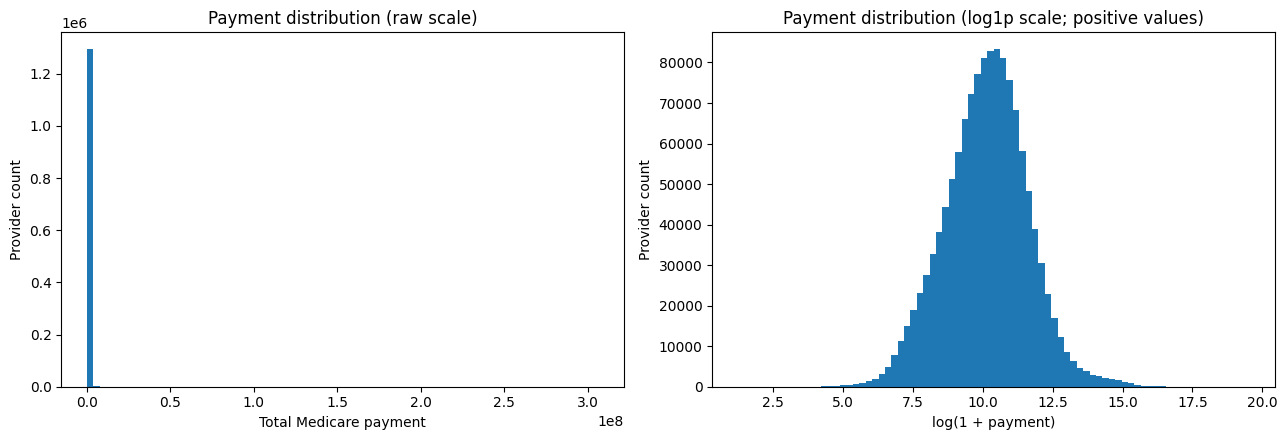

,payment_threshold,providers_at_or_above,observed_share_pct
0.9000,"151,995.9200",129674,10.0000
0.9500,"261,353.1230",64837,5.0000
0.9900,"1,141,640.4648",12968,1.0000


In [9]:
if TARGET in data.columns:
    target = pd.to_numeric(data[TARGET], errors="coerce")
    target_valid = target.dropna()
    display(target_valid.describe(percentiles=[.50, .75, .90, .95, .99]).to_frame("total_medicare_payment"))

    print("Missing:", int(target.isna().sum()))
    print("Zeros:", int((target == 0).sum()))
    print("Negative values:", int((target < 0).sum()))

    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
    axes[0].hist(target_valid, bins=80)
    axes[0].set_title("Payment distribution (raw scale)")
    axes[0].set_xlabel("Total Medicare payment")
    axes[0].set_ylabel("Provider count")

    positive_target = target_valid[target_valid > 0]
    if not positive_target.empty:
        axes[1].hist(np.log1p(positive_target), bins=80)
        axes[1].set_title("Payment distribution (log1p scale; positive values)")
        axes[1].set_xlabel("log(1 + payment)")
        axes[1].set_ylabel("Provider count")
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "target_payment_distributions.png", dpi=160, bbox_inches="tight")
    plt.show()

    thresholds = target_valid.quantile([.90, .95, .99]).rename("payment_threshold").to_frame()
    thresholds["providers_at_or_above"] = [int((target_valid >= t).sum()) for t in thresholds["payment_threshold"]]
    thresholds["observed_share_pct"] = thresholds["providers_at_or_above"] / len(target_valid) * 100
    display(thresholds)
    thresholds.to_csv(OUTPUT_DIR / "high_cost_threshold_candidates.csv")
else:
    print(f"Skipping target analysis because {TARGET!r} was not found.")

## 9. Categorical distributions: provider type and state

Use frequency tables and charts for the main categorical fields when present. These summaries help identify representation imbalances and possible stratification variables for RQ1. Categories with very small counts should be interpreted cautiously.

,provider_rows
Rndrng_Prvdr_Type,
Nurse Practitioner,203212
Physician Assistant,112514
Internal Medicine,93627
Family Practice,83639
Physical Therapist in Private Practice,77901
Certified Registered Nurse Anesthetist (CRNA),53495
Emergency Medicine,50101
Anesthesiology,41082
Diagnostic Radiology,32843


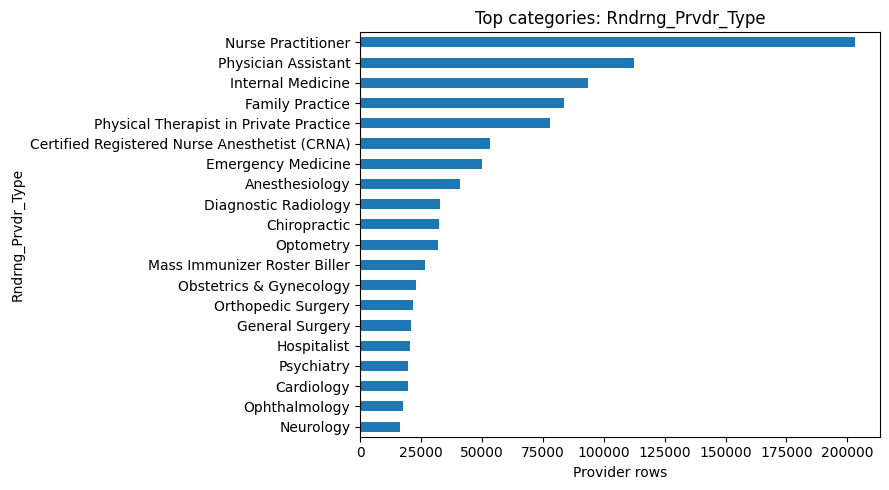

,provider_rows
Rndrng_Prvdr_State_Abrvtn,
CA,105363
NY,88642
TX,86803
FL,85872
PA,63361
OH,52310
IL,51368
NC,44655
MI,43221


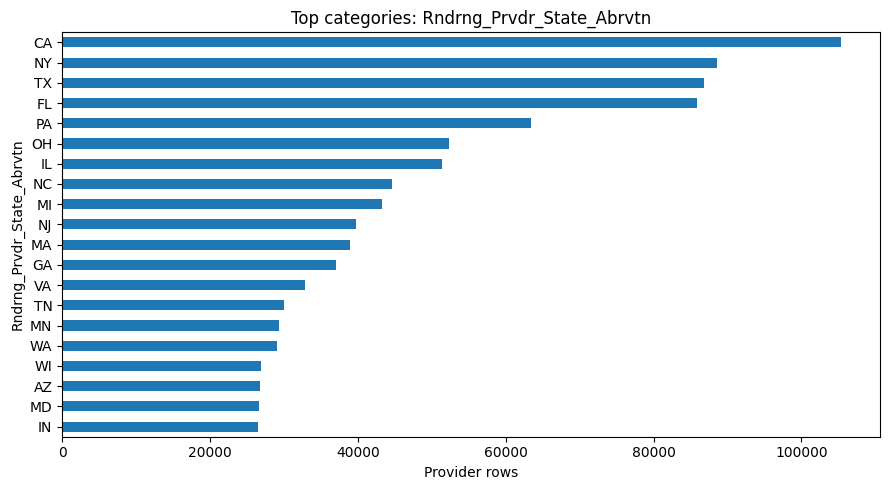

,provider_rows
Rndrng_Prvdr_Mdcr_Prtcptg_Ind,
Y,1295719
N,1020


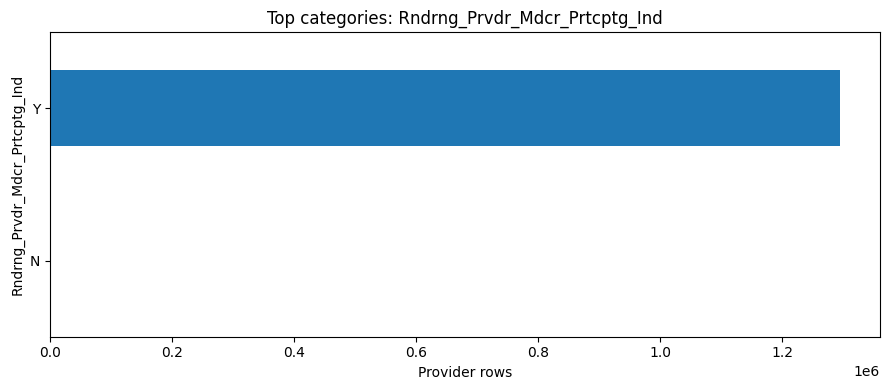

In [10]:
for col in ["Rndrng_Prvdr_Type", "Rndrng_Prvdr_State_Abrvtn", "Rndrng_Prvdr_Mdcr_Prtcptg_Ind"]:
    if col in data.columns:
        counts = data[col].astype("string").fillna("<MISSING>").value_counts(dropna=False)
        display(counts.head(25).rename_axis(col).to_frame("provider_rows"))
        counts.head(20).sort_values().plot(kind="barh", figsize=(9, max(4, .25 * min(20, len(counts)))))
        plt.title(f"Top categories: {col}")
        plt.xlabel("Provider rows")
        plt.tight_layout()
        plt.savefig(OUTPUT_DIR / f"category_{col}.png", dpi=160, bbox_inches="tight")
        plt.show()
    else:
        print(f"Column not found; skipped: {col}")

## 10. Bivariate analysis: payment by provider type

Compare provider-level payment distributions by provider type. Because payment totals are skewed and group sizes can differ substantially, show medians and quantiles rather than relying only on means. For readability, plot only the most common provider types. This is descriptive analysis; statistical tests and effect sizes should be selected after checking assumptions and defining the primary comparisons.

,count,mean,median,q75,q90
Rndrng_Prvdr_Type,,,,,
Diagnostic Radiology,32843,"125,242.5476","82,011.8100","142,401.5950","248,842.0580"
Internal Medicine,93627,"84,572.2401","44,569.1300","88,380.1950","166,689.0540"
Mass Immunizer Roster Biller,26738,"57,318.7002","40,010.6900","72,749.2125","124,035.3250"
Physical Therapist in Private Practice,77901,"45,599.2752","32,377.0900","58,790.6500","95,435.9800"
Emergency Medicine,50101,"40,378.0872","31,329.8100","51,291.4200","75,634.8700"
Family Practice,83639,"62,953.0790","31,326.4000","68,081.9250","125,731.4800"
Anesthesiology,41082,"33,079.1174","22,888.8300","36,541.5400","54,478.5560"
Optometry,31979,"29,511.9864","16,054.2400","35,837.0250","68,122.3320"
Nurse Practitioner,203212,"49,951.9143","13,301.4900","30,770.9350","68,411.4290"


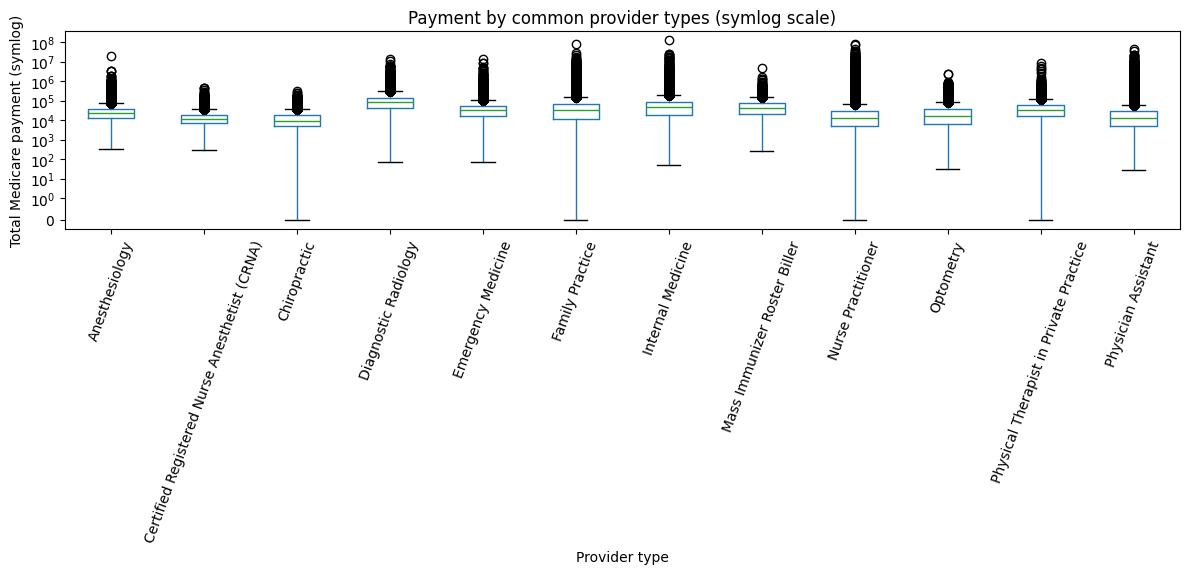

In [11]:
if TARGET in data.columns and "Rndrng_Prvdr_Type" in data.columns:
    tmp = data[["Rndrng_Prvdr_Type", TARGET]].copy()
    tmp[TARGET] = pd.to_numeric(tmp[TARGET], errors="coerce")
    tmp = tmp.dropna(subset=[TARGET, "Rndrng_Prvdr_Type"])
    top_types = tmp["Rndrng_Prvdr_Type"].value_counts().head(12).index
    grouped = (tmp[tmp["Rndrng_Prvdr_Type"].isin(top_types)]
               .groupby("Rndrng_Prvdr_Type")[TARGET]
               .agg(count="count", mean="mean", median="median",
                    q75=lambda s: s.quantile(.75), q90=lambda s: s.quantile(.90))
               .sort_values("median", ascending=False))
    display(grouped)
    grouped.to_csv(OUTPUT_DIR / "payment_by_provider_type_summary.csv")

    plot_data = tmp[tmp["Rndrng_Prvdr_Type"].isin(top_types)].copy()
    order = plot_data.groupby("Rndrng_Prvdr_Type")[TARGET].median().sort_values(ascending=False).index
    # Boxplots use a log scale for visibility; zeros are retained and handled via symlog.
    fig, ax = plt.subplots(figsize=(12, 6))
    plot_data.boxplot(column=TARGET, by="Rndrng_Prvdr_Type", rot=70, ax=ax, grid=False)
    ax.set_yscale("symlog", linthresh=1)
    ax.set_title("Payment by common provider types (symlog scale)")
    ax.set_xlabel("Provider type")
    ax.set_ylabel("Total Medicare payment (symlog)")
    plt.suptitle("")
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "payment_by_provider_type.png", dpi=160, bbox_inches="tight")
    plt.show()
else:
    print("Target or provider type column not found; skipped bivariate analysis.")

## 11. Correlation and target-leakage screening

Spearman correlations are a screening tool, not evidence of causation or a final feature-selection method. Very high association with payment-related variables may reflect mathematical overlap, shared components, or information that would not be available at prediction time.

At minimum, review `Tot_Mdcr_Alowd_Amt` and `Tot_Mdcr_Stdzd_Amt` before modeling. Also assess `Tot_Sbmtd_Chrg` and `Tot_Srvcs` based on the exact prediction use case. Exclude direct/near-direct payment measures from the primary model when they leak the target or are unavailable at the intended prediction time. Record the reason for every exclusion.


,spearman_corr_with_target
Tot_Mdcr_Alowd_Amt,0.9981
Tot_Mdcr_Stdzd_Amt,0.9980
Med_Mdcr_Stdzd_Amt,0.9681
Med_Mdcr_Pymt_Amt,0.9660
Med_Mdcr_Alowd_Amt,0.9577
Tot_Srvcs,0.8942
Tot_Sbmtd_Chrg,0.8891
Med_Tot_Srvcs,0.8853
Med_Sbmtd_Chrg,0.8332
Tot_Benes,0.8081


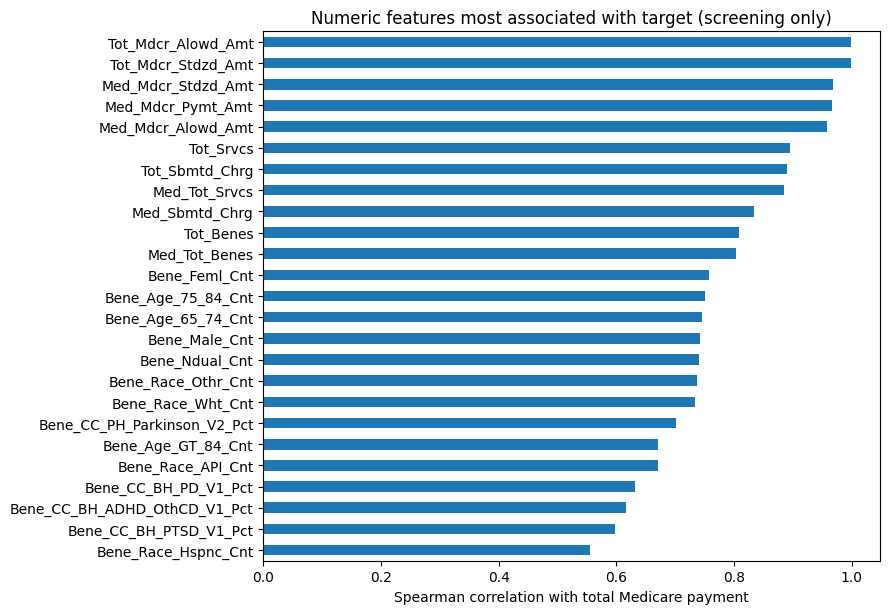

Review these potential leakage / timing-sensitive fields before modeling:
['Tot_Mdcr_Alowd_Amt', 'Tot_Mdcr_Stdzd_Amt', 'Tot_Sbmtd_Chrg', 'Tot_Srvcs']


In [12]:
if TARGET in data.columns:
    corr_frame = data.select_dtypes(include=np.number).copy()
    if TARGET in corr_frame.columns:
        corr = corr_frame.corr(method="spearman", numeric_only=True)[TARGET].drop(TARGET, errors="ignore").dropna()
        corr = corr.reindex(corr.abs().sort_values(ascending=False).index)
        display(corr.head(30).to_frame("spearman_corr_with_target"))
        corr.to_frame("spearman_corr_with_target").to_csv(OUTPUT_DIR / "spearman_correlations_with_target.csv")

        plt.figure(figsize=(9, max(5, .25 * min(25, len(corr.head(25))))))
        corr.head(25).sort_values().plot(kind="barh")
        plt.xlabel("Spearman correlation with total Medicare payment")
        plt.title("Numeric features most associated with target (screening only)")
        plt.tight_layout()
        plt.savefig(OUTPUT_DIR / "target_spearman_correlations.png", dpi=160, bbox_inches="tight")
        plt.show()

    leakage_candidates = [
        "Tot_Mdcr_Alowd_Amt", "Tot_Mdcr_Stdzd_Amt",
        "Tot_Sbmtd_Chrg", "Tot_Srvcs"
    ]
    print("Review these potential leakage / timing-sensitive fields before modeling:")
    print([c for c in leakage_candidates if c in data.columns])
else:
    print("Target not found; skipped correlation analysis.")

## 12. Cross-field consistency checks

The checks below are conditional on the corresponding columns existing. CMS suppression and reporting rules can make component sums differ from totals. A discrepancy is a review flag, not automatic proof of an error. Always consult the official data dictionary before deciding how to handle it.

In [13]:
def compare_sum_to_total(df, component_cols, total_col, label):
    available = [c for c in component_cols if c in df.columns]
    if total_col not in df.columns or len(available) < 2:
        print(f"Skipped {label}: required columns unavailable. Found components: {available}")
        return None
    comp = df[available].apply(pd.to_numeric, errors="coerce")
    total = pd.to_numeric(df[total_col], errors="coerce")
    complete = comp.notna().all(axis=1) & total.notna()
    diff = comp.sum(axis=1, min_count=len(available)) - total
    result = pd.DataFrame({
        "check": [label],
        "components_used": [", ".join(available)],
        "total_column": [total_col],
        "rows_with_complete_values": [int(complete.sum())],
        "rows_with_difference": [int((complete & diff.ne(0)).sum())],
        "rows_with_difference_pct_of_complete": [float((complete & diff.ne(0)).sum() / complete.sum() * 100) if complete.sum() else np.nan],
    })
    return result

checks = []
candidate_checks = [
    (["Bene_Age_0_64_Cnt", "Bene_Age_65_74_Cnt", "Bene_Age_75_84_Cnt", "Bene_Age_GT_84_Cnt"], "Tot_Benes", "Beneficiary age bands vs total beneficiaries"),
    (["Bene_Feml_Cnt", "Bene_Male_Cnt"], "Tot_Benes", "Sex counts vs total beneficiaries"),
    (["Bene_Dual_Cnt", "Bene_Ndual_Cnt"], "Tot_Benes", "Dual-status counts vs total beneficiaries"),
]
for comps, total_col, label in candidate_checks:
    result = compare_sum_to_total(data, comps, total_col, label)
    if result is not None:
        checks.append(result)

if checks:
    consistency = pd.concat(checks, ignore_index=True)
    display(consistency)
    consistency.to_csv(OUTPUT_DIR / "consistency_checks.csv", index=False)
else:
    print("No configured component-total checks could be run; verify actual column names against the CMS dictionary.")

,check,components_used,total_column,rows_with_complete_values,rows_with_difference,rows_with_difference_pct_of_complete
0,Beneficiary age bands vs total beneficiaries,"Bene_Age_65_74_Cnt, Bene_Age_75_84_Cnt, Bene_A...",Tot_Benes,532533,524090,98.4146
1,Sex counts vs total beneficiaries,"Bene_Feml_Cnt, Bene_Male_Cnt",Tot_Benes,1120401,0,0.0000
2,Dual-status counts vs total beneficiaries,"Bene_Dual_Cnt, Bene_Ndual_Cnt",Tot_Benes,832257,0,0.0000


## 13. Outlier review using IQR (flag only; do not automatically cap)

The supplied reference notebook uses the 1.5 × IQR rule and boxplots to flag potential outliers. For this Medicare project, use IQR only as a screening tool. Payment totals and utilization counts may have legitimate long right tails; automatic capping or deletion could remove the very high-cost providers the project is studying.

`IQR = Q3 - Q1`; lower flag = `Q1 - 1.5 × IQR`; upper flag = `Q3 + 1.5 × IQR`.

,column,q1,q3,iqr,lower_iqr_bound,upper_iqr_bound,flagged_count,flagged_pct_of_nonmissing,nonmissing_n
12,Drug_Sbmtd_Chrg,0.0000,0.0000,0.0000,0.0000,0.0000,253948,22.1780,1145043
15,Drug_Mdcr_Stdzd_Amt,0.0000,0.0000,0.0000,0.0000,0.0000,253948,22.1780,1145043
13,Drug_Mdcr_Alowd_Amt,0.0000,0.0000,0.0000,0.0000,0.0000,253948,22.1780,1145043
14,Drug_Mdcr_Pymt_Amt,0.0000,0.0000,0.0000,0.0000,0.0000,253948,22.1780,1145043
10,Drug_Tot_Benes,0.0000,0.0000,0.0000,0.0000,0.0000,253948,22.1780,1145043
11,Drug_Tot_Srvcs,0.0000,0.0000,0.0000,0.0000,0.0000,253948,22.1780,1145043
9,Drug_Tot_HCPCS_Cds,0.0000,0.0000,0.0000,0.0000,0.0000,253948,22.1780,1145043
57,Bene_CC_PH_Hyperlipidemia_V2_Pct,72.0000,75.0000,3.0000,67.5000,79.5000,192492,15.5810,1235428
1,Rndrng_Prvdr_RUCA,1.0000,1.0000,0.0000,1.0000,1.0000,196619,15.1724,1295902
47,Bene_CC_BH_PD_V1_Pct,0.0000,1.0000,1.0000,-1.5000,2.5000,64452,14.4946,444663


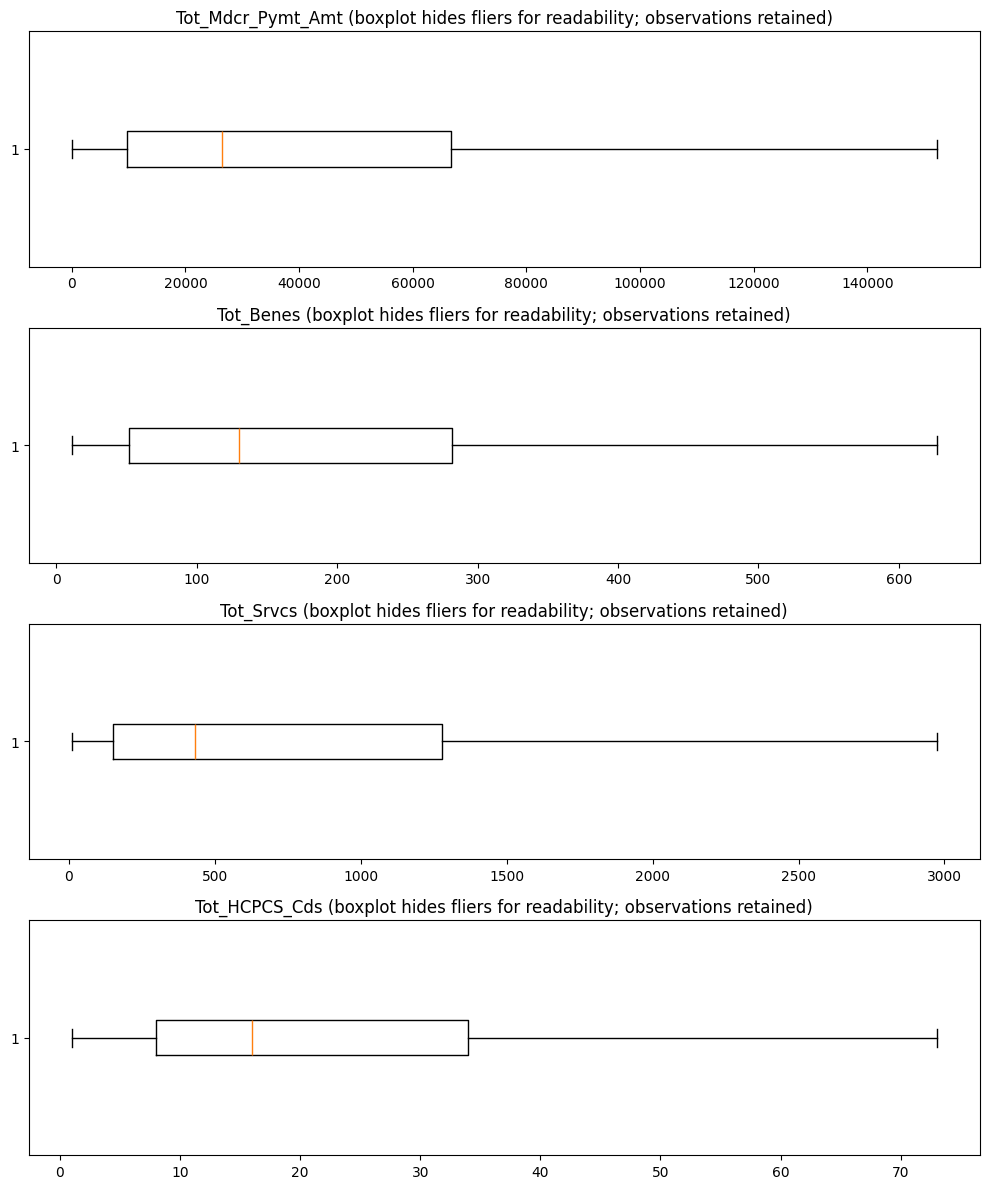

In [16]:
outlier_rows = []
for col in numeric_cols:
    s = pd.to_numeric(data[col], errors="coerce").replace([np.inf, -np.inf], np.nan).dropna()
    if s.empty or s.nunique() < 2:
        continue
    q1, q3 = s.quantile([.25, .75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = int(((s < low) | (s > high)).sum())
    outlier_rows.append({
        "column": col, "q1": q1, "q3": q3, "iqr": iqr,
        "lower_iqr_bound": low, "upper_iqr_bound": high,
        "flagged_count": n_out, "flagged_pct_of_nonmissing": n_out / len(s) * 100,
        "nonmissing_n": len(s)
    })
outlier_summary = pd.DataFrame(outlier_rows).sort_values("flagged_pct_of_nonmissing", ascending=False)
display(outlier_summary.head(30))
outlier_summary.to_csv(OUTPUT_DIR / "iqr_outlier_flags.csv", index=False)

# Boxplot of selected payment/utilization variables, if available.
plot_cols = [c for c in [TARGET, "Tot_Benes", "Tot_Srvcs", "Tot_HCPCS_Cds"] if c in data.columns]
if plot_cols:
    fig, axes = plt.subplots(len(plot_cols), 1, figsize=(10, 3 * len(plot_cols)))
    if len(plot_cols) == 1:
        axes = [axes]
    for ax, col in zip(axes, plot_cols):
        vals = pd.to_numeric(data[col], errors="coerce").dropna()
        ax.boxplot(vals, vert=False, showfliers=False)
        ax.set_title(f"{col} (boxplot hides fliers for readability; observations retained)")
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "selected_numeric_boxplots.png", dpi=160, bbox_inches="tight")
    plt.show()

## 14. Build an EDA evidence summary

This summary records actual outputs from the loaded file. Use these outputs to write the project boundary and limitations; do not copy expected results from earlier runs if the file version differs.

In [15]:
summary = {
    "input_file": str(DATA_PATH),
    "rows": int(data.shape[0]),
    "columns": int(data.shape[1]),
    "exact_duplicate_rows": int(data.duplicated().sum()),
    "target_column_present": TARGET in data.columns,
    "provider_id_column_present": NPI_COL in data.columns,
    "target_missing_count": int(data[TARGET].isna().sum()) if TARGET in data.columns else None,
    "target_zero_count": int((pd.to_numeric(data[TARGET], errors="coerce") == 0).sum()) if TARGET in data.columns else None,
    "top_10_missing_fields": missingness.head(10).to_dict(orient="records"),
}
if NPI_COL in data.columns:
    summary["provider_id_missing_count"] = int(data[NPI_COL].isna().sum())
    summary["duplicate_nonnull_provider_ids"] = int(data.loc[data[NPI_COL].notna(), NPI_COL].duplicated().sum())
if TARGET in data.columns:
    t = pd.to_numeric(data[TARGET], errors="coerce").dropna()
    summary["target_summary"] = {
        "mean": float(t.mean()), "median": float(t.median()),
        "p75": float(t.quantile(.75)), "p90": float(t.quantile(.90)),
        "p95": float(t.quantile(.95)), "p99": float(t.quantile(.99)),
        "max": float(t.max())
    }

with open(OUTPUT_DIR / "eda_summary.json", "w", encoding="utf-8") as f:
    json.dump(summary, f, indent=2, default=str)
display(pd.json_normalize(summary, sep="_").T.rename(columns={0:"value"}))
print("Wrote:", OUTPUT_DIR / "eda_summary.json")

,value
input_file,/content/drive/MyDrive/AI_ML-MS/Capstone Proje...
rows,1296739
columns,76
exact_duplicate_rows,0
target_column_present,True
provider_id_column_present,True
target_missing_count,0
target_zero_count,8
top_10_missing_fields,"[{'column': 'Med_Sprsn_Ind', 'missing_count': ..."
provider_id_missing_count,0


Wrote: /content/drive/MyDrive/AI_ML-MS/Capstone Project/qm640_project/reports/eda/eda_summary.json


## 15. Findings from the supplied EDA run

This section records the results supplied with this notebook (`eda_summary.json`, `missingness.csv`, `spearman_correlations_with_target.csv`, `payment_by_provider_type_summary.csv`, and the accompanying figures). Treat these as descriptive findings for the analyzed CMS 2024 provider-level file; rerun the notebook on the same source file to reproduce them.

### 15.1 Dataset integrity and target coverage

- The dataset contains **1,296,739 provider rows and 76 columns**.
- The provider identifier `Rndrng_NPI` is present, has no missing values, and has **1,296,739 distinct non-null values**. No duplicate non-null provider identifiers were reported.
- There are **zero exact duplicate rows**.
- The target `Tot_Mdcr_Pymt_Amt` is present with **zero missing values** and **8 zero-payment rows**.
- The target distribution is strongly right-skewed: mean `$92,584.47`, median `$26,513.00`, 75th percentile `$66,672.41`, 90th percentile `$151,995.92`, 95th percentile `$261,353.12`, 99th percentile `$1,141,640.46`, and maximum `$306,357,782.68`.

The mean being substantially larger than the median, together with the long right tail in the distribution plots, indicates that a relatively small number of provider records have very high reported payment totals. Use robust summaries (median and percentiles) alongside the mean. The 90th-percentile value can serve as a candidate high-cost cutoff, but it is a study-defined label, not an official CMS classification. Establish the cutoff using training data only when evaluating predictive models.

### 15.2 Missingness and suppression

The most incomplete fields in the supplied results are:

| Field | Missing values | Missing (%) |
|---|---:|---:|
| `Med_Sprsn_Ind` | 1,145,043 | 88.30 |
| `Drug_Sprsn_Ind` | 1,145,043 | 88.30 |
| `Bene_Race_API_Cnt` | 1,062,540 | 81.94 |
| `Bene_Race_Othr_Cnt` | 1,052,600 | 81.17 |
| `Bene_Race_Hspnc_Cnt` | 988,886 | 76.26 |
| `Bene_Race_Black_Cnt` | 924,899 | 71.32 |
| `Bene_CC_BH_PTSD_V1_Pct` | 882,169 | 68.03 |
| `Bene_CC_BH_ADHD_OthCD_V1_Pct` | 875,024 | 67.48 |
| `Bene_CC_BH_PD_V1_Pct` | 852,076 | 65.71 |
| `Bene_Race_NatInd_Cnt` | 848,880 | 65.46 |

Missingness is concentrated in suppression indicators, beneficiary race counts, and several beneficiary condition measures. Do not automatically replace these values with zero: a missing value can mean suppressed, unavailable, or not applicable rather than “none.” Before modeling, document the CMS field definitions and suppression rules, quantify missingness by target/provider groups where appropriate, and compare defensible strategies (for example, complete-case analysis versus imputation plus missingness indicators). High-missingness features may need to be excluded from a primary model or assessed in a sensitivity analysis.

### 15.3 Provider mix and geography

The category plots show that **Nurse Practitioner** is the largest displayed provider-type category, followed by **Physician Assistant** and **Internal Medicine**. The largest displayed state counts are **California (CA), New York (NY), Texas (TX), and Florida (FL)**. The Medicare participation indicator is overwhelmingly displayed as `Y` in the supplied plot; inspect the underlying frequency table for any rare or missing categories before deciding whether this variable is useful for modeling.

These are provider-row counts, not population-adjusted provider rates and not payment comparisons. Differences in the number of records by state or specialty should not be interpreted as differences in cost or quality without accounting for provider mix, volume, and other relevant factors.

### 15.4 Payment differences by provider type

For the 12 provider types summarized in the supplied output, **Diagnostic Radiology** has the highest median total Medicare payment (`$82,011.81; n = 32,843`), followed by **Internal Medicine** (`$44,569.13; n = 93,627`). The Nurse Practitioner category has the largest count among the displayed types (**n = 203,212**) and a median payment of `$13,301.49`. Physician Assistants have **n = 112,514** and a median of `$12,626.45`.

The observed distributions are highly dispersed and contain extreme high values. These descriptive comparisons do not establish that provider type independently causes higher payment. Formal RQ1 comparisons should use an appropriate inferential approach and account for skewness, unequal group sizes, and relevant confounding variables. Report effect sizes and uncertainty, not only p-values.

### 15.5 Spearman association and leakage risk

The strongest supplied numeric Spearman associations with `Tot_Mdcr_Pymt_Amt` are:

| Feature | Spearman correlation |
|---|---:|
| `Tot_Mdcr_Alowd_Amt` | 0.9981 |
| `Tot_Mdcr_Stdzd_Amt` | 0.9980 |
| `Med_Mdcr_Stdzd_Amt` | 0.9681 |
| `Med_Mdcr_Pymt_Amt` | 0.9660 |
| `Med_Mdcr_Alowd_Amt` | 0.9577 |
| `Tot_Srvcs` | 0.8942 |
| `Tot_Sbmtd_Chrg` | 0.8891 |
| `Med_Tot_Srvcs` | 0.8853 |
| `Med_Sbmtd_Chrg` | 0.8332 |
| `Tot_Benes` | 0.8081 |

These are screening correlations, not causal effects. In particular, payment/allowed/standardized payment fields are closely related by construction to the payment target and should be treated as **potential target leakage** in a model intended to predict total payment from independent provider characteristics. Service, charge, and beneficiary-volume fields may also be unavailable at the intended prediction time or may encode much of the same utilization scale. Define the prediction time and exclude direct target components from the primary model; document any alternative model that intentionally uses them. Recalculate feature associations after applying the approved feature-eligibility rules.

### 15.6 Cross-field consistency check requiring investigation

The supplied consistency checks report that female and male beneficiary counts sum to `Tot_Benes` for all **1,120,401** rows with complete values, and dual-status/non-dual-status counts sum to `Tot_Benes` for all **832,257** complete rows. In contrast, the three displayed age-band counts (`Bene_Age_65_74_Cnt`, `Bene_Age_75_84_Cnt`, and `Bene_Age_GT_84_Cnt`) differ from `Tot_Benes` in **524,090 of 532,533 complete rows (98.41%)**.

Do not silently “fix” these age-band values. Verify the data dictionary definitions, whether age groups cover the same beneficiary universe as `Tot_Benes`, and whether suppression or reporting rules explain the mismatch. Until resolved, avoid treating the age-band sum as a validated identity and document this as a data-definition/consistency limitation.

### 15.7 Outliers and distribution handling

The payment and utilization boxplots show long upper tails and many potential extreme values. The raw payment histogram is compressed by the maximum, while the log-transformed view makes the central distribution easier to inspect. The notebook’s boxplots hide fliers for readability only; the observations remain in the data. Do not delete, cap, or winsorize high values solely because an IQR rule flags them. Investigate data definitions and sensitivity to transformations, and retain legitimate high-volume providers unless a documented data-quality rule justifies exclusion.

### 15.8 Implications for the four research questions

- **RQ1 — Group differences:** Compare payment distributions across provider types and other pre-specified groups using robust summaries, suitable tests, effect sizes, and uncertainty intervals. Address unequal group sizes and skewness.
- **RQ2 — Payment prediction:** Establish a prediction-time feature policy, remove direct payment-derived fields and other leakage candidates, and compare a baseline with appropriate regression models using held-out data and metrics such as MAE and RMSE.
- **RQ3 — High-cost identification:** Define “high cost” with a training-set percentile cutoff, compare classification models against a simple baseline, and report precision, recall, F1, ROC-AUC/PR-AUC as appropriate, plus calibration where useful.
- **RQ4 — Provider risk scoring:** Test whether a score ranks high-payment providers usefully on held-out data; evaluate lift or precision among the top-ranked providers and assess stability across provider types and states. A high payment amount alone is not evidence of inappropriate billing or fraud.

### 15.9 Interpretation boundary

This is provider-level, aggregated observational data. Associations do not establish causation, individual patient-level risk, care quality, fraud, or inappropriate payment. Findings should be framed as patterns in reported Medicare payment and utilization that may support further review, not as determinations about individual providers.


## 16. Interpretation, limitations, and decisions to document

### Data-supported boundaries
- **Unit of analysis:** provider/NPI aggregate record, not an individual claim or patient.
- **Target:** `Tot_Mdcr_Pymt_Amt`, after confirming the CMS definition in the data dictionary.
- **Population:** only the population represented by the selected CMS file and reporting year.
- **High-cost definition:** pre-specify a percentile threshold (90th percentile is the initial candidate from the baseline analysis) and state that it is a research-defined label, not an official CMS risk label.
- **Feature eligibility:** exclude direct payment components and features unavailable at the intended prediction time from the primary predictive model.

### Limitations to assess from actual outputs
- Missingness and privacy suppression may reduce usable sample size and affect subgroup comparisons.
- Capped/top-coded chronic-condition measures, where present, limit interpretation above the published cap.
- One reporting year limits temporal generalization and cannot establish future-year predictive performance.
- Right skew and extreme values can affect squared-error metrics. Report MAE and RMSE and consider a justified log-target sensitivity analysis.
- Provider-level aggregation prevents patient-level or claim-level conclusions.
- Association and predictive ranking do not establish causality, fraud, waste, abuse, or provider quality.

### Data-quality decision log
For each issue, record: **issue, evidence/output file, decision, justification, and impact on RQ1–RQ4**. Do not drop or winsorize records solely because the IQR rule flags them. Preserve an untouched source copy and create a separate modeling dataset after documenting decisions.
